### this script reshuffles the first or the last based on that one of them is fixed

In [2]:
import pandas as pd
import numpy as np
import itertools
from tqdm import tqdm
import random
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pub_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/pub_author.csv"
pub_df = pd.read_csv(pub_path)
pub_df.head()

,ost_bk,cluster_id,cntry,role,year,dis
0,29768070,65683243.0,JPN,F,2008,51
1,29768070,79129017.0,JPN,M,2008,51
2,29768070,58951927.0,CHN,M,2008,51
3,29768070,9735544.0,JPN,M,2008,51
4,29768070,34120990.0,JPN,L,2008,51


In [3]:
pub_cntrys = pub_df.groupby(['ost_bk','year','dis'])['cntry'].apply(list).reset_index()

In [5]:
pub_cntrys.head()

,ost_bk,year,dis,cntry
0,29768070,2008,51,"[JPN, JPN, CHN, JPN, JPN]"
1,29768104,2008,61,"[USA, USA, USA, DEU]"
2,29768126,2008,18,"[ISL, ISL, USA, USA, ISL, USA, USA, ISL, ISL, ..."
3,29768150,2008,26,"[CHN, JPN, JPN, CHN, CHN, CHN]"
4,29768191,2008,44,"[USA, CHN, CHN, GBR, CHN, CHN]"


In [16]:
def generate_expectation(df, n, position):
    
    expect_res = pd.DataFrame()
    
    def random_shuffling(df):
        reshuffle_res = []
        for row in df.values:
            pub_id = row[0]
            year = row[1]
            cntrys = row[3]
            if position=='last':
                #Fixed first author, sample for last author
                first = cntrys[0]
                last = random.sample(cntrys[1:], 1)[0]
            else: 
                #Fixed last author, sample for first author
                last = cntrys[-1]
                first = random.sample(cntrys[:-1], 1)[0]
                
            reshuffle_res.append([pub_id, year, first, last])
            
        reshuffle_res = pd.DataFrame(reshuffle_res, columns=['ost_bk','year','first','last'])
        reshuffle_res = reshuffle_res.groupby(['year','first','last']).size().reset_index(name='exp')
        return reshuffle_res
        
    for _ in tqdm(range(n)):
        reshuffle_res = random_shuffling(df)
        expect_res = pd.concat([expect_res, reshuffle_res])
    
    expect_res = expect_res.groupby(['year','first','last'])['exp'].sum().reset_index()
    expect_res['exp'] = expect_res['exp']/n
    return expect_res

In [28]:
fixed_first_exp = generate_expectation(pub_cntrys, 100, 'last')

100%|█████████████████████████████████████████| 100/100 [21:46<00:00, 13.06s/it]


In [4]:
fixed_first_exp = pd.read_csv("fixed_first_exp.csv")

In [29]:
fixed_last_exp = generate_expectation(pub_cntrys, 100, 'first')

100%|█████████████████████████████████████████| 100/100 [21:46<00:00, 13.06s/it]


In [3]:
fixed_first_exp = pd.read_csv("../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/fixed_first.csv")
fixed_last_exp = pd.read_csv("../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/fixed_last.csv")

In [4]:
raw_df = pd.read_csv("../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/pub_pair_raw.csv")

In [6]:
first_last_df = pub_df[pub_df.role!='M']
first_last_df = first_last_df.pivot(index=['ost_bk','year'], columns=['role'], values='cntry').reset_index()
raw_df = first_last_df.groupby(['year','F','L']).size().reset_index(name='raw')
raw_df = raw_df.rename(columns={'F':'first','L':'last'})
raw_df.head()

,year,first,last,raw
0,2008,AFG,GBR,1
1,2008,AFG,IND,1
2,2008,AGO,BRA,1
3,2008,ALB,ALB,2
4,2008,ALB,FRA,1


In [7]:
group_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
group_df = pd.read_csv(group_path)
group_dict = dict(zip(group_df['Code'],group_df['class']))

In [8]:
def cntry_to_group(df, group_dict):
    df['first_class'] = df['first'].map(group_dict)
    df['last_class'] = df['last'].map(group_dict)
    return df

In [9]:
raw_df = cntry_to_group(raw_df, group_dict)
fixed_first = cntry_to_group(fixed_first_exp, group_dict)
fixed_last = cntry_to_group(fixed_last_exp,group_dict)

In [10]:
fixed_first.head()

,year,first,last,exp,first_class,last_class
0,2008,AFG,AFG,0.69,Lagging,Lagging
1,2008,AFG,GBR,0.21,Lagging,Advanced
2,2008,AFG,IND,1.00,Lagging,Proficient
3,2008,AFG,NLD,0.10,Lagging,Advanced
4,2008,AGO,BRA,1.00,Lagging,Proficient


In [11]:
grouped_raw = raw_df.groupby(['first_class','last_class'])['raw'].sum().reset_index(name='raw')
grouped_fixed_first = fixed_first.groupby(['first_class','last_class'])['exp'].sum().reset_index(name='fixed_first')
grouped_fixed_last = fixed_last.groupby(['first_class','last_class'])['exp'].sum().reset_index(name='fixed_last')

In [12]:
fixed_first_norm = grouped_raw.merge(grouped_fixed_first, on=['first_class','last_class'])
fixed_first_norm['norm'] = np.log(fixed_first_norm['raw']/fixed_first_norm['fixed_first'])

In [13]:
fixed_first_norm

,first_class,last_class,raw,fixed_first,norm
0,Advanced,Advanced,1644372,1577952.78,0.041230
1,Advanced,Developing,25101,33894.80,-0.300354
2,Advanced,Lagging,33798,50179.00,-0.395195
3,Advanced,Proficient,119140,160384.42,-0.297274
4,Developing,Advanced,74490,61198.63,0.196540
5,Developing,Developing,87561,105559.40,-0.186938
6,Developing,Lagging,14303,12316.89,0.149498
7,Developing,Proficient,24336,21615.08,0.118566
8,Lagging,Advanced,75834,65240.76,0.150462
9,Lagging,Developing,10913,10826.42,0.007965


In [14]:
color_scheme_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv'

In [19]:
color_scheme.head()

,class,color,type
0,Advanced,#D96C94,st
1,Proficient,#F88A4D,st
2,Developing,#5DC97C,st
3,Lagging,#23A5D9,st
4,High,#D96C94,income


In [20]:
color_scheme = pd.read_csv(color_scheme_path)
color_scheme = color_scheme[color_scheme['type']=='st']
color_dict = dict(zip(color_scheme['class'], color_scheme['color']))

In [21]:
fixed_first_norm['color'] = fixed_first_norm['last_class'].map(color_dict)
fixed_first_norm.loc[fixed_first_norm['norm'] < 0, 'color'] = '#D9D9D9'

In [22]:
fixed_first_norm

,first_class,last_class,raw,fixed_first,norm,color
0,Advanced,Advanced,1644372,1577952.78,0.041230,#D96C94
1,Advanced,Developing,25101,33894.80,-0.300354,#D9D9D9
2,Advanced,Lagging,33798,50179.00,-0.395195,#D9D9D9
3,Advanced,Proficient,119140,160384.42,-0.297274,#D9D9D9
4,Developing,Advanced,74490,61198.63,0.196540,#D96C94
5,Developing,Developing,87561,105559.40,-0.186938,#D9D9D9
6,Developing,Lagging,14303,12316.89,0.149498,#23A5D9
7,Developing,Proficient,24336,21615.08,0.118566,#F88A4D
8,Lagging,Advanced,75834,65240.76,0.150462,#D96C94
9,Lagging,Developing,10913,10826.42,0.007965,#5DC97C


In [29]:
import matplotlib.patches as mpatches

In [40]:
def plot_normalization(df, xlabel, color_dict):
    
    fig, ax = plt.subplots()
    sns.barplot(x='first_class', y='norm', hue='last_class', hue_order=color_dict.keys(), order=color_dict.keys(), 
                data=df[df.norm>0],
               palette=color_dict,
               ax=ax)
    sns.barplot(x='first_class', y='norm', hue='last_class', hue_order=color_dict.keys(), order=color_dict.keys(),
                data=df[df.norm<0],
               color='#D9D9D9',
               ax=ax)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel("Log(Actually/Expectation)", fontsize=12)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.tick_params(axis='both', which='minor', labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    legend_patches = [
        mpatches.Patch(color=color, label=label) for label, color in color_dict.items()
    ]
    ax.legend(handles=legend_patches, loc=[1.01,0.4],frameon=False)
    
    return fig, ax

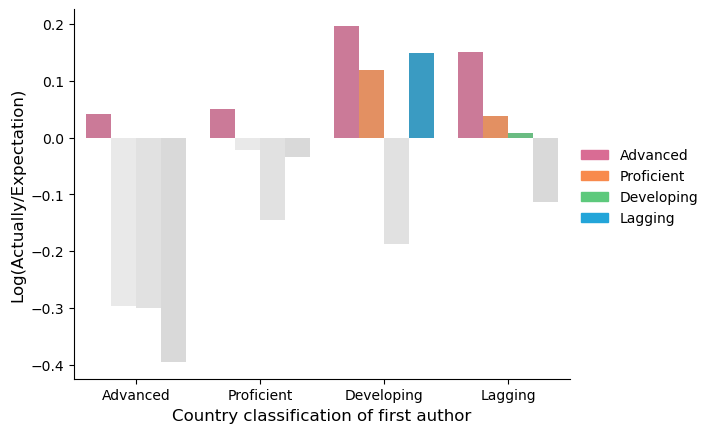

In [41]:
fig, ax=plot_normalization(fixed_first_norm,'Country classification of first author',color_dict)

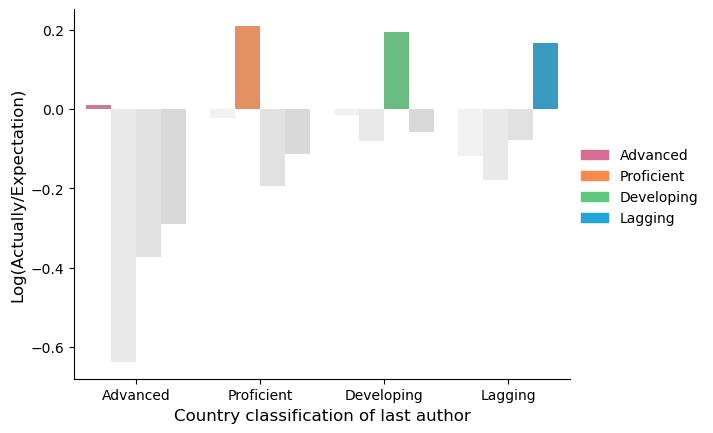

In [44]:
fig, ax = plot_normalization(fixed_last_norm, 'Country classification of last author', color_dict)

In [43]:
fixed_last_norm = grouped_raw.merge(grouped_fixed_last, on=['first_class','last_class'])
fixed_last_norm['norm'] = np.log(fixed_last_norm['raw']/fixed_last_norm['fixed_last'])

In [23]:
fixed_last_norm.sort_values(by='last_class')

,first_class,last_class,raw,fixed_last,norm
0,Advanced,Advanced,1644372,1626305.35,0.011048
4,Developing,Advanced,74490,75529.15,-0.013854
8,Lagging,Advanced,75834,85329.48,-0.117973
12,Proficient,Advanced,345700,353232.02,-0.021554
1,Advanced,Developing,25101,36454.73,-0.373164
5,Developing,Developing,87561,72031.64,0.195230
9,Lagging,Developing,10913,11815.00,-0.079415
13,Proficient,Developing,15244,18517.63,-0.194537
2,Advanced,Lagging,33798,45161.55,-0.289844
6,Developing,Lagging,14303,15131.10,-0.056283


In [46]:
grouped_raw

,first_class,last_class,raw
0,Advanced,Advanced,1644372
1,Advanced,Developing,25101
2,Advanced,Lagging,33798
3,Advanced,Proficient,119140
4,Developing,Advanced,74490
5,Developing,Developing,87561
6,Developing,Lagging,14303
7,Developing,Proficient,24336
8,Lagging,Advanced,75834
9,Lagging,Developing,10913


In [47]:
first_last_pair = pd.read_csv("../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/first_last_pair.csv")
first_last_pair.head()

,year,first,last,exp
0,2008,AFG,AFG,1.73
1,2008,AFG,CAN,0.10
2,2008,AFG,DEU,0.42
3,2008,AFG,EGY,0.10
4,2008,AFG,GBR,0.55


In [48]:
first_last_pair = cntry_to_group(first_last_pair, group_dict)

In [49]:
grouped_first_last = first_last_pair.groupby(['first_class','last_class'])['exp'].sum().reset_index(name='exp')
first_last_norm = grouped_raw.merge(grouped_first_last, on=['first_class','last_class'])
first_last_norm['norm'] = np.log(first_last_norm['raw']/first_last_norm['exp'])

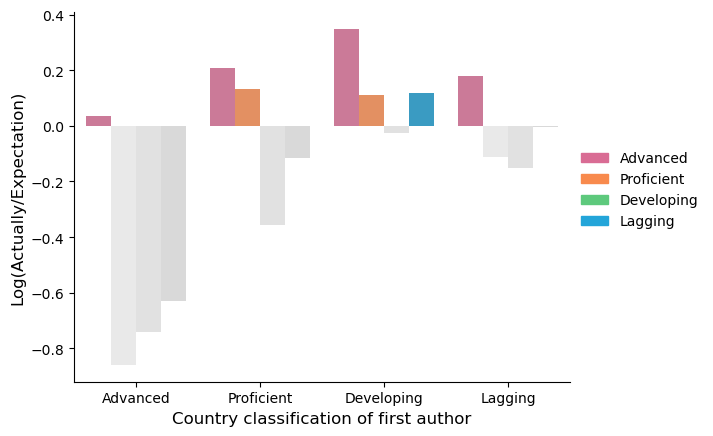

In [51]:
fig, ax = plot_normalization(first_last_norm, 'Country classification of first author', color_dict)